# ERCOT Ridge solver comparison

Reproduce the preliminary Ridge fit and compare three solvers on the same quadratic objective. Run the cells in order. Results are written to `optimization/results/ridge/`.

## 1. Set up the experiment

Fix the regularization strength, relative gradient tolerance, iteration cap, and timing repeats.

In [1]:
import json
import platform
from pathlib import Path

from IPython.display import Image, display
from time import perf_counter

import matplotlib
import numpy as np
import pandas as pd
import sklearn
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

matplotlib.use("Agg")
from matplotlib import pyplot as plt


working_dir = Path.cwd().resolve()
locations = (
    working_dir,
    working_dir / "optimization",
    working_dir / "final project" / "ERCOT Project" / "optimization",
)
HERE = next(
    (path for path in locations if path.name == "optimization" and (path.parent / "preliminary").is_dir()),
    None,
)
if HERE is None:
    raise FileNotFoundError("Start the kernel from optimization/, the ERCOT Project root, or the course workspace.")
PRELIMINARY = HERE.parent / "preliminary"
ALPHA = 0.1
RELATIVE_TOLERANCE = 1e-8
MAX_ITERATIONS = 10_000
REPEATS = 5


## 2. Build the predictors and check the shared forecast dates

Use the same 12 predictors and complete-day rules as the preliminary Ridge notebook. The saved forecasts share 301 complete days.

In [2]:
def hourly_examples():
    """Recreate the 12 predictors and complete-day rules in the Ridge notebook."""
    hourly = pd.read_csv(
        PRELIMINARY / "ercot_system_hourly_cleaned.csv",
        usecols=["timestamp", "system_total_mw"],
        parse_dates=["timestamp"],
    )
    hourly["date"] = hourly["timestamp"].dt.normalize()
    hourly["hour"] = hourly["timestamp"].dt.hour
    counts = hourly.groupby("date")["hour"].agg(["size", "nunique"])
    dates = counts.index[(counts["size"] == 24) & (counts["nunique"] == 24)]
    daily = hourly[hourly["date"].isin(dates)].pivot(
        index="date", columns="hour", values="system_total_mw"
    )
    yesterday = dates - pd.Timedelta(days=1)
    last_week = dates - pd.Timedelta(days=7)
    valid = yesterday.isin(dates) & last_week.isin(dates)
    dates = dates[valid]
    yesterday_load = daily.loc[yesterday[valid]].to_numpy()
    week_load = daily.loc[last_week[valid]].to_numpy()
    hours = np.tile(np.arange(24), len(dates))
    target_dates = dates.repeat(24)
    hour_angle = 2 * np.pi * hours / 24
    day_of_week = target_dates.day_of_week
    dow_angle = 2 * np.pi * day_of_week / 7
    month_angle = 2 * np.pi * target_dates.month / 12
    features = np.column_stack([
        yesterday_load.ravel(), week_load.ravel(),
        yesterday_load.mean(axis=1).repeat(24), yesterday_load.max(axis=1).repeat(24),
        yesterday_load.min(axis=1).repeat(24),
        np.sin(hour_angle), np.cos(hour_angle), np.sin(dow_angle), np.cos(dow_angle),
        np.sin(month_angle), np.cos(month_angle), day_of_week >= 5,
    ])
    return features, daily.loc[dates].to_numpy().ravel(), target_dates + pd.to_timedelta(hours, unit="h")


def errors(actual, forecast):
    residual = np.asarray(forecast) - np.asarray(actual)
    return {"mae_mw": np.abs(residual).mean(), "rmse_mw": np.sqrt(np.mean(residual ** 2))}


def shared_baselines():
    ml = pd.read_csv(PRELIMINARY / "ercot_ml_24hour_forecasts.csv", parse_dates=["timestamp"])
    lstm = pd.read_csv(
        PRELIMINARY / "lstm_outputs" / "lstm_day_ahead_forecasts.csv", parse_dates=["timestamp"]
    )
    shared = ml.merge(lstm[lstm["split"] == "test"], on="timestamp", validate="one_to_one")
    days = shared.groupby(shared["timestamp"].dt.normalize()).size()
    if len(days) != 301 or not (days == 24).all():
        raise ValueError("The preliminary exports must share 301 complete forecast days.")
    actual = shared["actual_load_mw"].to_numpy()
    np.testing.assert_array_equal(actual, shared["actual_mw"].to_numpy())
    models = {
        "Previous day": "naive_prev_day_mw", "Previous week": "naive_prev_week_mw",
        "Ridge": "ridge_forecast_mw", "RBF-SVR": "svr_forecast_mw", "LSTM": "lstm_mw",
    }
    return pd.DataFrame([
        {"model": model, "days": len(days), "hours": len(shared), **errors(actual, shared[column])}
        for model, column in models.items()
    ])



baselines = shared_baselines()
display(baselines)


,model,days,hours,mae_mw,rmse_mw
0,Previous day,301,7224,2393.228241,3370.568649
1,Previous week,301,7224,4606.454624,6339.624951
2,Ridge,301,7224,2294.084907,3199.906507
3,RBF-SVR,301,7224,2351.173854,3302.769315
4,LSTM,301,7224,1691.652477,2501.626167


## 3. Fit the reference objective

Fit the scaler on the training period, center the problem to leave the intercept unpenalized, and compare the reference fit to the saved Ridge predictions.

In [3]:
x, y, timestamps = hourly_examples()
train, val, test = timestamps.year <= 2023, timestamps.year.isin([2024, 2025]), timestamps.year == 2026
scaler = StandardScaler().fit(x[train])
scaled = scaler.transform(x)
mean_x, mean_y = scaled[train].mean(axis=0), y[train].mean()
centered_x, centered_y = scaled[train] - mean_x, y[train] - mean_y
n, d = centered_x.shape
hessian = (centered_x.T @ centered_x + ALPHA * np.eye(d)) / n
rhs = (centered_x.T @ centered_y) / n

reference = Ridge(alpha=ALPHA, solver="cholesky").fit(scaled[train], y[train])
reference_val = reference.predict(scaled[val])
saved = pd.read_csv(PRELIMINARY / "ercot_ml_24hour_forecasts.csv", parse_dates=["timestamp"])
np.testing.assert_array_equal(timestamps[test].to_numpy(), saved["timestamp"].to_numpy())
np.testing.assert_array_equal(y[test], saved["actual_load_mw"].to_numpy())
reference_test = reference.predict(scaled[test])
saved_diff = np.max(np.abs(reference_test - saved["ridge_forecast_mw"].to_numpy()))
if saved_diff > 0.1:
    raise ValueError(f"Reference predictions differ from the saved Ridge forecast by {saved_diff:.3f} MW.")

print(f"Maximum difference from saved Ridge test forecast: {saved_diff:.9g} MW")


Maximum difference from saved Ridge test forecast: 2.47382559e-10 MW


## 4. Compare the solvers

Run fixed-step gradient descent, Armijo gradient descent, and conjugate gradient from zero coefficients. Compare the median timing run for each solver.

In [4]:
def solve(hessian, rhs, method):
    """Minimize a quadratic with gradient H @ w - rhs from zero coefficients."""
    started = perf_counter()
    weights = np.zeros_like(rhs)
    gradient = -rhs
    squared_norm = float(gradient @ gradient)
    tolerance_squared = RELATIVE_TOLERANCE ** 2 * squared_norm
    direction = -gradient
    trials = 0
    fixed_step = 1 / np.linalg.eigvalsh(hessian)[-1] if method == "fixed_gd" else None
    trace = [(perf_counter() - started, weights, np.sqrt(squared_norm), trials)]

    while squared_norm > tolerance_squared and len(trace) <= MAX_ITERATIONS:
        if method == "cg":
            curvature = hessian @ direction
            step = squared_norm / (direction @ curvature)
            weights = weights + step * direction
            new_gradient = hessian @ weights - rhs
            new_squared_norm = float(new_gradient @ new_gradient)
            direction = -new_gradient + (new_squared_norm / squared_norm) * direction
        else:
            step = fixed_step
            if method == "armijo_gd":
                step = 1.0
                quadratic_curvature = float(gradient @ (hessian @ gradient))
                # Evaluate the exact objective change to avoid subtracting nearly equal costs.
                while True:
                    trials += 1
                    change = -step * squared_norm + 0.5 * step ** 2 * quadratic_curvature
                    if change <= -1e-4 * step * squared_norm:
                        break
                    step *= 0.5
            weights = weights - step * gradient
            new_gradient = hessian @ weights - rhs
            new_squared_norm = float(new_gradient @ new_gradient)

        gradient, squared_norm = new_gradient, new_squared_norm
        trace.append((perf_counter() - started, weights, np.sqrt(squared_norm), trials))

    return trace, squared_norm <= tolerance_squared



methods = {
    "fixed_gd": "Fixed-step GD", "armijo_gd": "Armijo GD", "cg": "Conjugate gradient",
}
summary, history = [], []
reference_gradient = hessian @ reference.coef_ - rhs
with threadpool_limits(limits=1, user_api="blas"):
    for key, label in methods.items():
        runs = [solve(hessian, rhs, key) for _ in range(REPEATS)]
        runs.sort(key=lambda run: run[0][-1][0])
        trace, converged = runs[REPEATS // 2]
        for iteration, (elapsed, weights, grad_norm, trials) in enumerate(trace):
            delta = weights - reference.coef_
            gap = delta @ reference_gradient + 0.5 * delta @ hessian @ delta
            history.append({
                "method": label, "iteration": iteration, "elapsed_ms": 1000 * elapsed,
                "objective_gap": gap, "gradient_norm": grad_norm, "line_search_evaluations": trials,
            })
        predictions = (scaled[val] - mean_x) @ trace[-1][1] + mean_y
        max_diff = np.max(np.abs(predictions - reference_val))
        summary.append({
            **history[-1], "converged": converged,
            "validation_agrees_with_reference": max_diff <= 0.1,
            "max_validation_difference_mw": max_diff, **errors(y[val], predictions),
        })


display(pd.DataFrame(summary))


,method,iteration,elapsed_ms,objective_gap,gradient_norm,line_search_evaluations,converged,validation_agrees_with_reference,max_validation_difference_mw,mae_mw,rmse_mw
0,Fixed-step GD,10000,48.1269,5.455677e-04,2.216460e-03,0,False,False,1.681424e-01,2307.950710,3298.094588
1,Armijo GD,4749,35.4797,3.706732e-06,1.985191e-04,9501,True,True,1.378785e-02,2307.950327,3298.093989
2,Conjugate gradient,13,0.1215,3.330246e-15,1.085687e-07,0,True,True,1.877779e-07,2307.950302,3298.093942


## 5. Save and inspect convergence

The two panels show the training objective gap by iteration and elapsed time. Validation error and prediction agreement are in the solver summary.

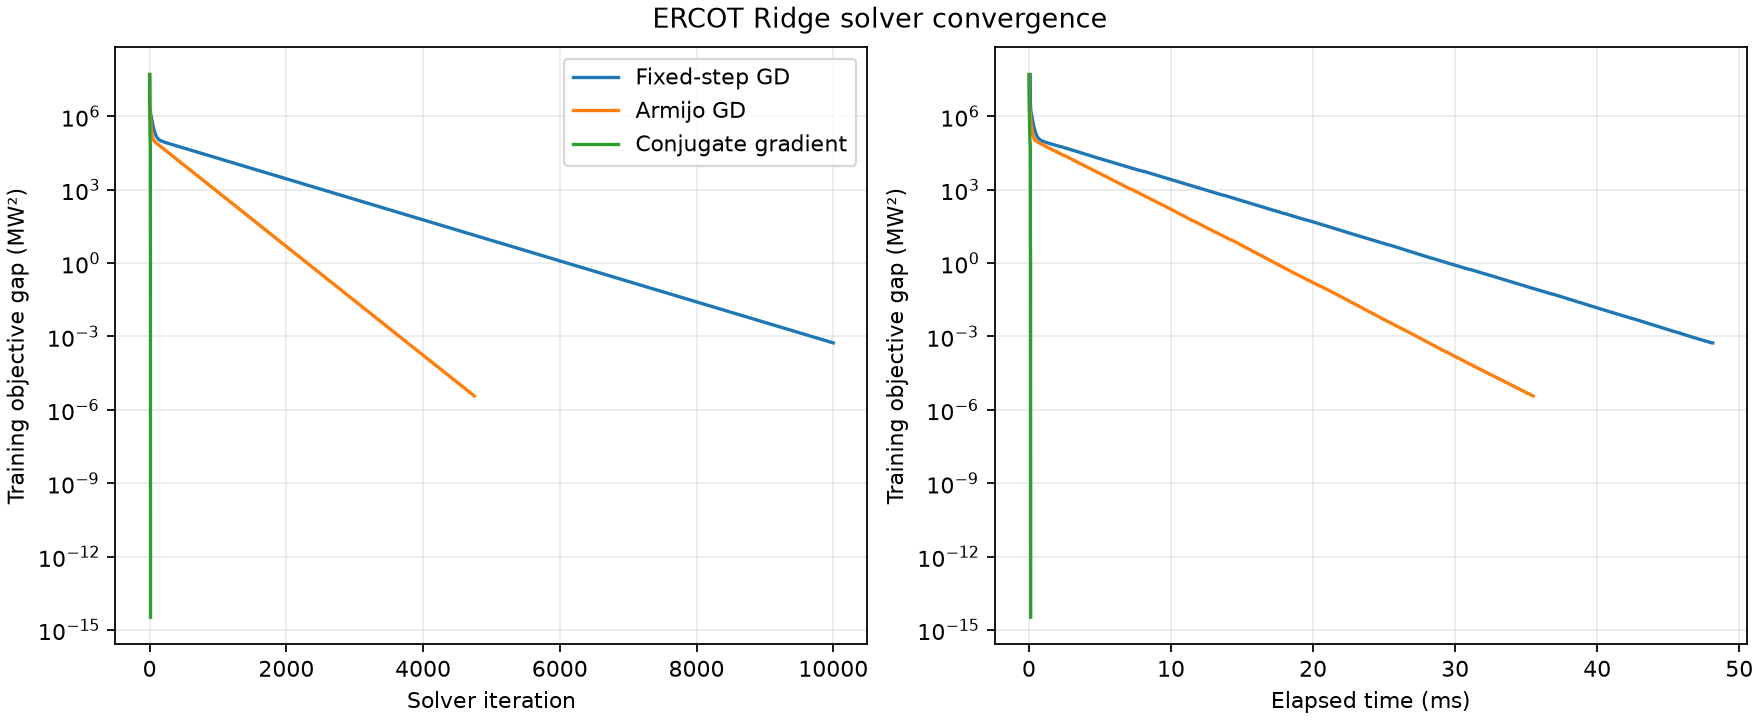

In [5]:
def plot_convergence(history, output_dir):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained")
    for method, points in history.groupby("method", sort=False):
        positive = points[points["objective_gap"] > 0]
        for axis, x in zip(axes, ["iteration", "elapsed_ms"]):
            axis.semilogy(positive[x], positive["objective_gap"], label=method)
    for axis, label in zip(axes, ["Solver iteration", "Elapsed time (ms)"]):
        axis.set(xlabel=label, ylabel="Training objective gap (MW²)")
        axis.grid(alpha=0.25)
    axes[0].legend()
    fig.suptitle("ERCOT Ridge solver convergence")
    fig.savefig(output_dir / "convergence.png", dpi=160)
    plt.close(fig)

output_dir = HERE / "results" / "ridge"
output_dir.mkdir(parents=True, exist_ok=True)
history = pd.DataFrame(history)
summary = pd.DataFrame(summary)
settings = {
    "notebook": "optimization/ridge_solvers.ipynb",
    "alpha": ALPHA, "relative_gradient_tolerance": RELATIVE_TOLERANCE,
    "iteration_cap": MAX_ITERATIONS, "timing_repeats": REPEATS, "timing_blas_threads": 1,
    "training_hours": int(train.sum()), "validation_hours": int(val.sum()),
    "test_hours": int(test.sum()), "max_difference_from_saved_test_forecast_mw": saved_diff,
    "reference_validation": errors(y[val], reference_val),
    "python": platform.python_version(), "platform": platform.platform(),
    "processor": platform.processor(), "numpy": np.__version__, "pandas": pd.__version__,
    "scikit_learn": sklearn.__version__, "matplotlib": matplotlib.__version__,
}
(output_dir / "settings.json").write_text(json.dumps(settings, indent=2) + "\n", encoding="utf-8")
history.to_csv(output_dir / "history.csv", index=False)
summary.to_csv(output_dir / "solver_summary.csv", index=False)
baselines.to_csv(output_dir / "shared_baselines.csv", index=False)
plot_convergence(history, output_dir)
display(Image(filename=str(output_dir / "convergence.png")))
